# 06.5 · DBSCAN and Gaussian mixtures

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/05-dbscan-gmm/lesson.ipynb)

Read the [README](README.md) and label the ten points (core / border / noise) on paper first. This notebook:

1. Checks your DBSCAN labels and draws them.
2. Shows DBSCAN finding crescent shapes that K-Means cannot.
3. Chooses eps with a k-distance plot and runs DBSCAN on ShopWave customers.
4. Fits a Gaussian mixture: the by-hand soft membership, then real customers.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. DBSCAN on ten points

In [2]:
names = list("PQRSTUVWXY")
points = np.array([[1, 1], [1, 2], [2, 1], [2, 2], [3, 2],
                   [6, 6], [6, 7], [7, 6], [8, 7], [4, 8]], dtype=float)

In [3]:
from sklearn.cluster import DBSCAN
from scipy.spatial.distance import cdist

def dbscan_table(points, eps, min_samples):
    """Neighbour counts and point kinds, next to DBSCAN's labels."""
    db = DBSCAN(eps=eps, min_samples=min_samples).fit(points)
    core = np.zeros(len(points), bool); core[db.core_sample_indices_] = True
    near = cdist(points, points) <= eps
    kind = np.where(core, "core", np.where(db.labels_ == -1, "noise", "border"))
    return pd.DataFrame({"neighbours": [", ".join(np.array(names)[row]) for row in near],
                         "count": near.sum(axis=1), "kind": kind, "cluster": db.labels_}, index=names)

In [4]:
dbscan_table(points, eps=1.5, min_samples=3)

,neighbours,count,kind,cluster
P,"P, Q, R, S",4,core,0
Q,"P, Q, R, S",4,core,0
R,"P, Q, R, S, T",5,core,0
S,"P, Q, R, S, T",5,core,0
T,"R, S, T",3,core,0
U,"U, V, W",3,core,1
V,"U, V, W",3,core,1
W,"U, V, W, X",4,core,1
X,"W, X",2,border,1
Y,Y,1,noise,-1


Compare with your table: P, Q, R, S, T are core and form cluster 0; U, V, W are core and X is a border point of cluster 1; Y is noise (label −1).

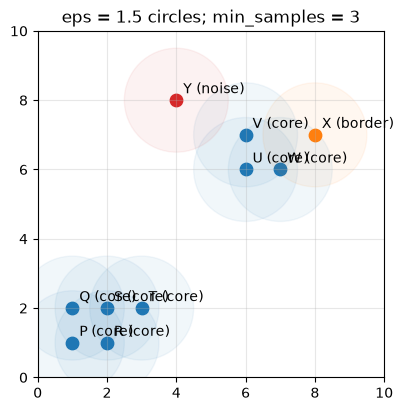

In [5]:
t = dbscan_table(points, eps=1.5, min_samples=3)
colours = {"core": "tab:blue", "border": "tab:orange", "noise": "tab:red"}
fig, ax = plt.subplots(figsize=(5, 4.5))
for (x, y), n, k in zip(points, names, t["kind"]):
    ax.add_patch(plt.Circle((x, y), 1.5, color=colours[k], alpha=0.06))
    ax.scatter(x, y, color=colours[k], s=80); ax.annotate(f"{n} ({k})", (x, y), xytext=(5, 5), textcoords="offset points")
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.set_aspect("equal"); ax.grid(alpha=.3)
ax.set_title("eps = 1.5 circles; min_samples = 3"); plt.show()

## 2. Shapes K-Means cannot handle

Two interlocking crescents. The **adjusted Rand index** (ARI) compares a clustering with the true crescents: 1 = perfect, 0 = chance.

In [6]:
from sklearn.datasets import make_moons
moons, moon_truth = make_moons(n_samples=300, noise=0.06, random_state=42)

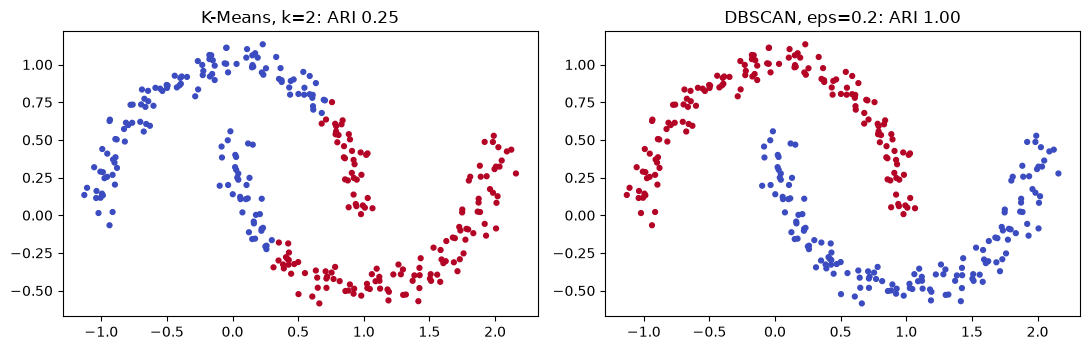

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

km_lab = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(moons)
db_lab = DBSCAN(eps=0.2, min_samples=5).fit_predict(moons)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, lab, title in zip(axes, [km_lab, db_lab], ["K-Means, k=2", "DBSCAN, eps=0.2"]):
    ax.scatter(moons[:, 0], moons[:, 1], c=lab, cmap="coolwarm", s=12)
    ax.set_title(f"{title}: ARI {adjusted_rand_score(moon_truth, lab):.2f}")
plt.tight_layout(); plt.show()

K-Means can only draw straight borders between centres, so it cuts both crescents in half. DBSCAN follows the crowd along each crescent.

## 3. DBSCAN on ShopWave customers

In [8]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)    # 2011-12-10
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
print(f"{len(sales):,} rows, {len(rfm):,} customers, snapshot {snapshot.date()}")

392,693 rows, 4,338 customers, snapshot 2011-12-10


In [9]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)                         # tame the long right tails
X = StandardScaler().fit_transform(rfm_log)      # mean 0, std 1 per column
print("X shape:", X.shape)

X shape: (4338, 3)


### Choosing eps: the k-distance plot

For every customer, the distance to their 6th-nearest neighbour (6 = `min_samples`), sorted. Crowded customers have small values; the curve shoots up where crowds end.

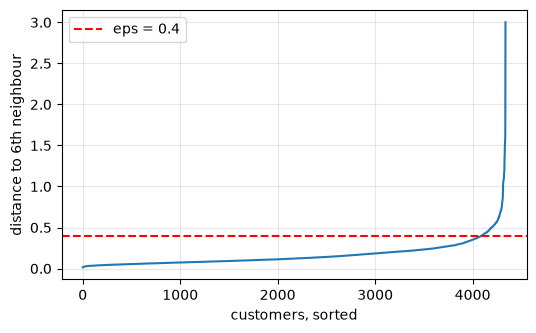

percentiles 50/90/95/98/99: [0.12 0.31 0.42 0.57 0.71]


In [10]:
from sklearn.neighbors import NearestNeighbors

dists, _ = NearestNeighbors(n_neighbors=6).fit(X).kneighbors(X)
kdist = np.sort(dists[:, -1])
plt.figure(figsize=(6, 3.5))
plt.plot(kdist); plt.axhline(0.4, color="red", linestyle="--", label="eps = 0.4")
plt.xlabel("customers, sorted"); plt.ylabel("distance to 6th neighbour"); plt.legend(); plt.grid(alpha=.3)
plt.show()
print("percentiles 50/90/95/98/99:", np.percentile(kdist, [50, 90, 95, 98, 99]).round(2))

In [11]:
for eps in [0.2, 0.3, 0.4, 0.5]:
    lab = DBSCAN(eps=eps, min_samples=6).fit_predict(X)
    print(f"eps {eps}: {lab.max() + 1} clusters, {(lab == -1).sum()} noise customers")

eps 0.2: 28 clusters, 797 noise customers
eps 0.3: 5 clusters, 305 noise customers
eps 0.4: 5 clusters, 139 noise customers
eps 0.5: 5 clusters, 73 noise customers


In [12]:
rfm["dbscan"] = DBSCAN(eps=0.4, min_samples=6).fit_predict(X)
rfm.groupby("dbscan").agg(customers=("recency", "size"),
                          recency_median=("recency", "median"),
                          orders_min=("frequency", "min"), orders_median=("frequency", "median"),
                          orders_max=("frequency", "max"), spend_median=("monetary", "median")).round(0)

,customers,recency_median,orders_min,orders_median,orders_max,spend_median
dbscan,,,,,,
-1,139,10.0,1,7.0,209,7205.0
0,1888,24.0,3,5.0,38,1600.0
1,1472,133.0,1,1.0,1,256.0
2,826,61.0,2,2.0,2,544.0
3,6,0.0,20,24.0,28,13140.0
4,7,0.0,10,11.0,17,4206.0


Row −1 is the **noise**: 139 customers that sit in no crowd. Their median spend is about ten times the typical customer's. These are the accounts finance asked about.

The clusters follow the **whole-number** nature of frequency: look at the `orders_min` and `orders_max` columns. One-order customers form one dense sheet, two-order customers another, and everyone with more orders a third. Two tiny clusters are very active customers who bought in the last day. That is real structure, but not a marketing segmentation. DBSCAN's strength here is the noise label.

## 4. Gaussian mixtures

### The by-hand example

Group 1: mean £20, sd £5. Group 2: mean £50, sd £10. Equal weights. A customer averages £32 per order.

In [13]:
from scipy.stats import norm

x = 32
like1, like2 = norm.pdf(x, 20, 5), norm.pdf(x, 50, 10)
p1 = 0.5 * like1 / (0.5 * like1 + 0.5 * like2)
print(f"N(32 | 20, 5)  = {like1:.5f}")
print(f"N(32 | 50, 10) = {like2:.5f}")
print(f"P(group 1 | 32) = {p1:.2f}   P(group 2 | 32) = {1 - p1:.2f}")

N(32 | 20, 5)  = 0.00448
N(32 | 50, 10) = 0.00790
P(group 1 | 32) = 0.36   P(group 2 | 32) = 0.64


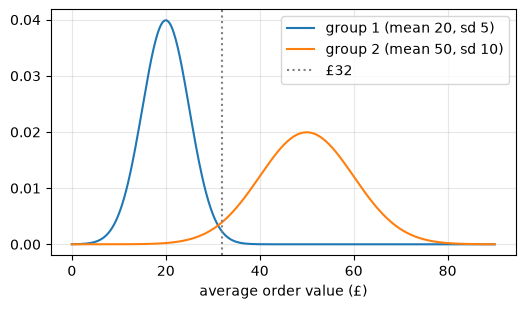

In [14]:
xs = np.linspace(0, 90, 400)
plt.figure(figsize=(6, 3.2))
plt.plot(xs, 0.5 * norm.pdf(xs, 20, 5), label="group 1 (mean 20, sd 5)")
plt.plot(xs, 0.5 * norm.pdf(xs, 50, 10), label="group 2 (mean 50, sd 10)")
plt.axvline(32, color="gray", linestyle=":", label="£32")
plt.xlabel("average order value (£)"); plt.legend(); plt.grid(alpha=.3); plt.show()

At £32 the wide group-2 curve is higher than the narrow group-1 curve, even though £32 is nearer 20. K-Means, which only looks at distance to centres, would say group 1.

### Real customers

In [15]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=4, n_init=3, random_state=42).fit(X)
proba = gm.predict_proba(X)
top = proba.max(axis=1)
print("component sizes:", sorted(np.bincount(proba.argmax(axis=1)).tolist(), reverse=True))
print(f"top probability > 0.9: {(top > 0.9).mean():.1%} of customers")
print(f"no component above 0.6: {(top < 0.6).mean():.1%} of customers")

component sizes: [1493, 1098, 912, 835]
top probability > 0.9: 78.6% of customers
no component above 0.6: 3.1% of customers


What did each component capture? Look at the order counts inside each:

In [16]:
rfm.assign(component=proba.argmax(axis=1)).groupby("component").agg(
    customers=("recency", "size"), orders_min=("frequency", "min"), orders_max=("frequency", "max"),
    recency_median=("recency", "median"), spend_median=("monetary", "median")).round(0)

,customers,orders_min,orders_max,recency_median,spend_median
component,,,,,
0,1098,3,7,44.0,1126.0
1,1493,1,1,131.0,256.0
2,835,2,2,61.0,547.0
3,912,3,209,8.0,2781.0


Two components hold **exactly** the one-order and the two-order customers: the same whole-number sheets DBSCAN found. A bell curve squeezed onto a sheet of identical frequencies is a modelling artefact, not a persona. The other two components split everyone with 3 or more orders into a moderate group and a heavy-buyer group.

### Who is in between?

In [17]:
unsure = rfm[["recency", "frequency", "monetary"]].assign(top_probability=top).nsmallest(5, "top_probability")
pd.concat([unsure, pd.DataFrame(proba[np.argsort(top)[:5]].round(2), index=unsure.index,
                                columns=[f"p{j}" for j in range(4)])], axis=1)

,recency,frequency,monetary,top_probability,p0,p1,p2,p3
Customer ID,,,,,,,,
14883.0,18,6,761.59,0.500005,0.5,0.0,0.0,0.5
15862.0,8,4,832.88,0.500448,0.5,0.0,0.0,0.5
15297.0,10,3,641.94,0.501145,0.5,0.0,0.0,0.5
17988.0,11,7,201.12,0.501618,0.5,0.0,0.0,0.5
15379.0,169,7,3703.29,0.501623,0.5,0.0,0.0,0.5


These customers are split 50/50 between two components: the moderate and the heavy buyers. They all have a few orders, and could reasonably be called either. Marketing can treat this list differently (e.g. test both messages) instead of forcing a label.

In [18]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(X)
print(f"agreement with K-Means (ARI): {adjusted_rand_score(km4, proba.argmax(axis=1)):.2f}")

agreement with K-Means (ARI): 0.43


Moderate agreement: mixture components can be stretched and tilted, K-Means clusters cannot, so the borders fall in different places.

## Quiz answers

1. **eps**: the neighbourhood radius. **min_samples**: how many points (including itself) must lie within eps for a point to count as core.
2. **Core**: at least min_samples neighbours within eps. **Border**: fewer, but within eps of a core point. **Noise**: neither.
3. DBSCAN grows clusters by chaining neighbouring dense points, so a cluster can follow any path. K-Means assigns each point to its nearest centre, which always produces straight borders and round-ish regions.
4. A **probability** of belonging to each cluster, rather than one hard label, so you can see how sure the assignment is.
5. Group 2 is **wider** (sd 10 vs 5). Measured in its own standard deviations, £32 is closer to group 2's centre (1.8 sd) than to group 1's (2.4 sd), so group 2's bell curve is higher at £32.

**Next:** [06.6 PCA](../06-pca/)